##Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

Matplotlib is building the font cache; this may take a moment.


In [3]:
df = pd.read_csv('data/data.csv')
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.shape

(1000, 8)

In [5]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [8]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

In [9]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [10]:

print("Categories in 'gender' variable:     ", end=" ")
print(df['gender'].unique())

print("Categories in 'race/ethnicity' variable: ", end=" ")
print(df['race_ethnicity'].unique())

print("Categories in 'parental level of education' variable:", end=" ")
print(df['parental_level_of_education'].unique())

print("Categories in 'lunch' variable:     ", end=" ")
print(df['lunch'].unique())

print("Categories in 'test preparation course' variable: ", end=" ")
print(df['test_preparation_course'].unique())

Categories in 'gender' variable:      <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race/ethnicity' variable:  <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in 'parental level of education' variable: <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable:      <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test preparation course' variable:  <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [14]:
# define numerical & categorical columns
numeric_features = df.select_dtypes(exclude="object").columns.tolist()
categorical_features = df.select_dtypes(include="object").columns.tolist()

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 3 numerical features : ['math_score', 'reading_score', 'writing_score']

We have 5 categorical features : ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


In [15]:
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average_score'] = df['total_score'] / 3
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [16]:
reading_full = len(df[df['reading_score'] == 100])
writing_full = len(df[df['writing_score'] == 100])
math_full = len(df[df['math_score'] == 100])

print(f'Number of students with full marks in Maths: {math_full}')
print(f'Number of students with full marks in Writing: {writing_full}')
print(f'Number of students with full marks in Reading: {reading_full}')

Number of students with full marks in Maths: 7
Number of students with full marks in Writing: 14
Number of students with full marks in Reading: 17


In [19]:
reading_less_20 = len(df[df['reading_score'] <= 20])
writing_less_20 = len(df[df['writing_score'] <= 20])
math_less_20 = len(df[df['math_score'] <= 20])

print(f'Number of students with less than 20 marks in Maths: {math_less_20}')
print(f'Number of students with less than 20 marks in Writing: {writing_less_20}')
print(f'Number of students with less than 20 marks in Reading: {reading_less_20}')

Number of students with less than 20 marks in Maths: 4
Number of students with less than 20 marks in Writing: 3
Number of students with less than 20 marks in Reading: 1


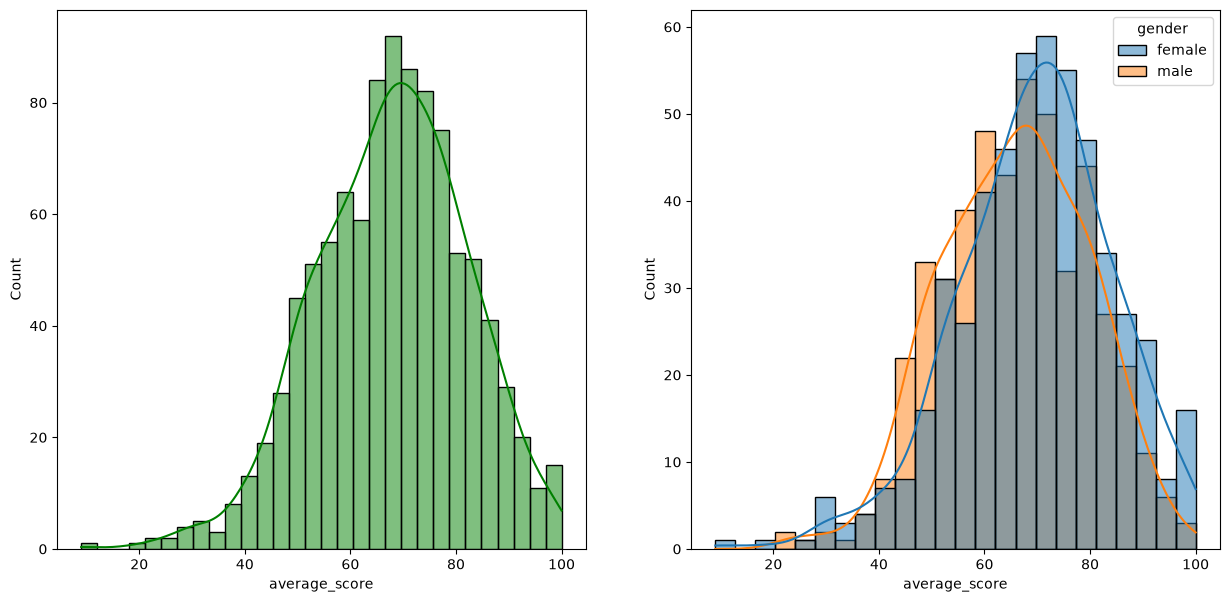

In [21]:

fig, axs = plt.subplots(1, 2, figsize=(15, 7))

plt.subplot(121)
sns.histplot(data=df, x='average_score', bins=30, kde=True, color='g')

plt.subplot(122)
sns.histplot(data=df, x='average_score', kde=True, hue='gender')

plt.show()

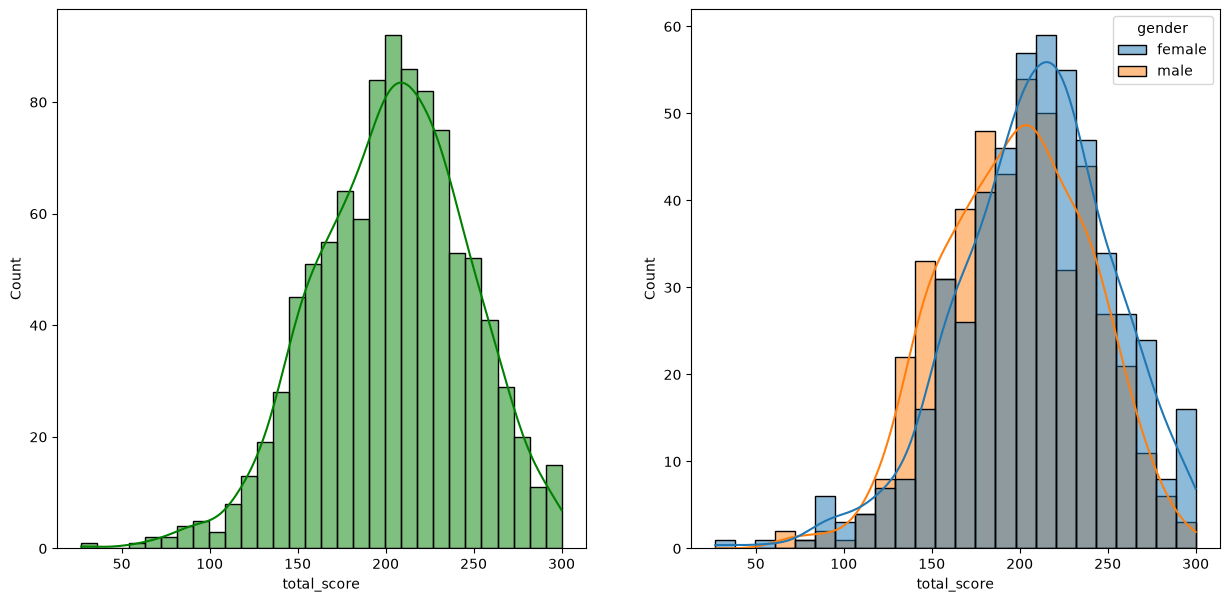

In [22]:

fig, axs = plt.subplots(1, 2, figsize=(15, 7))

plt.subplot(121)
sns.histplot(data=df, x='total_score', bins=30, kde=True, color='g')

plt.subplot(122)
sns.histplot(data=df, x='total_score', kde=True, hue='gender')

plt.show()

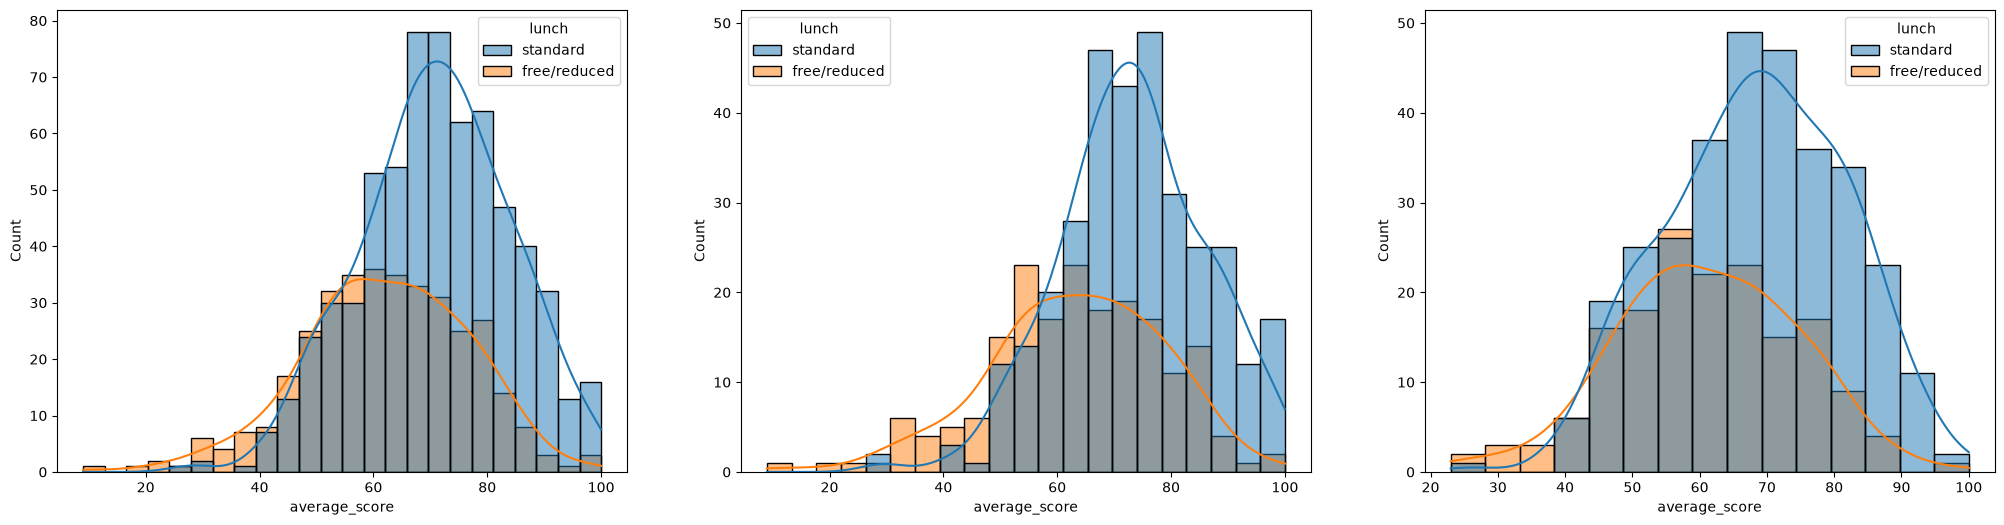

In [26]:
plt.subplots(1, 3, figsize=(25, 6))

order = ['standard', 'free/reduced']

plt.subplot(131)
sns.histplot(data=df, x='average_score', kde=True, hue='lunch', hue_order=order)

plt.subplot(132)
sns.histplot(data=df[df['gender']=='female'], x='average_score', kde=True, hue='lunch', hue_order=order)

plt.subplot(133)
sns.histplot(data=df[df['gender']=='male'], x='average_score', kde=True, hue='lunch', hue_order=order)

plt.show()

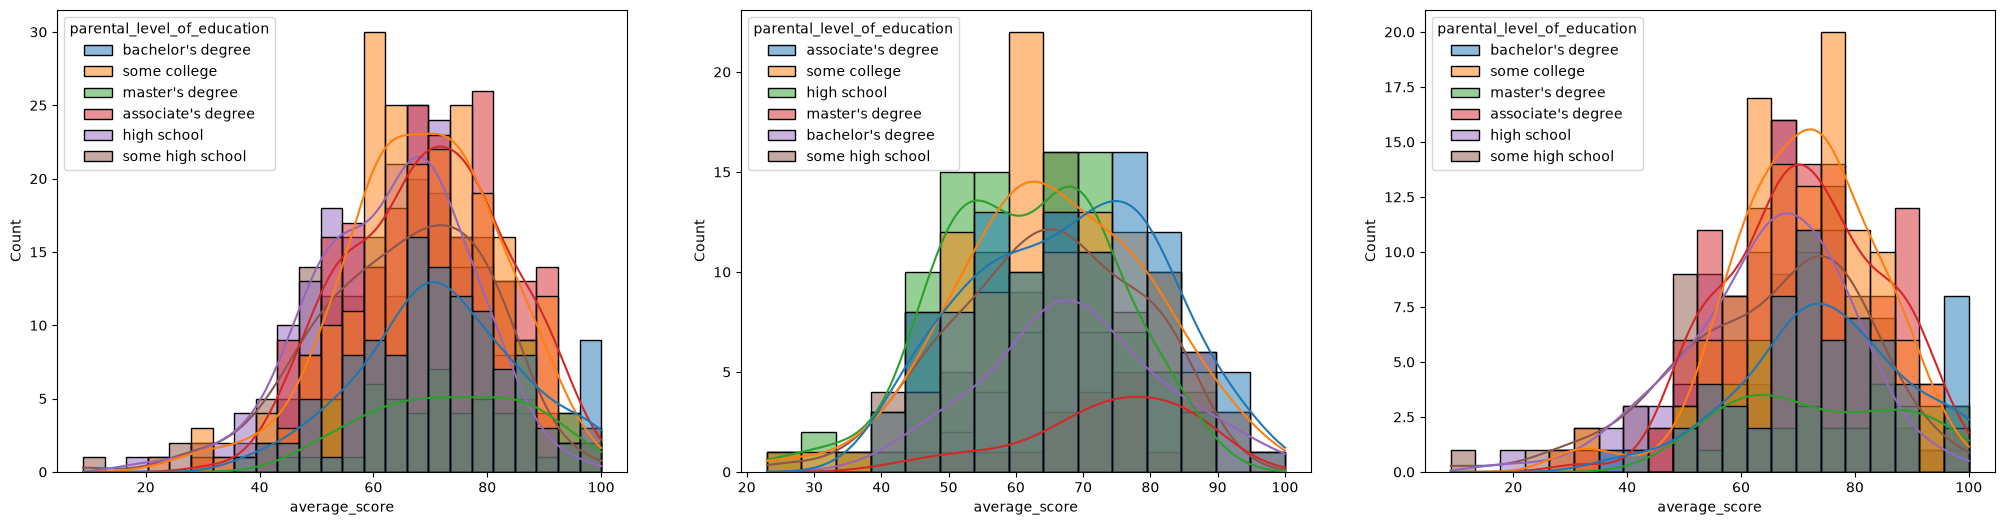

In [28]:
plt.subplots(1, 3, figsize=(25, 6))

plt.subplot(131)
sns.histplot(data=df, x='average_score', kde=True, hue='parental_level_of_education')

plt.subplot(132)
sns.histplot(data=df[df['gender']=='male'], x='average_score', kde=True, hue='parental_level_of_education')

plt.subplot(133)
sns.histplot(data=df[df['gender']=='female'], x='average_score', kde=True, hue='parental_level_of_education')

plt.show()

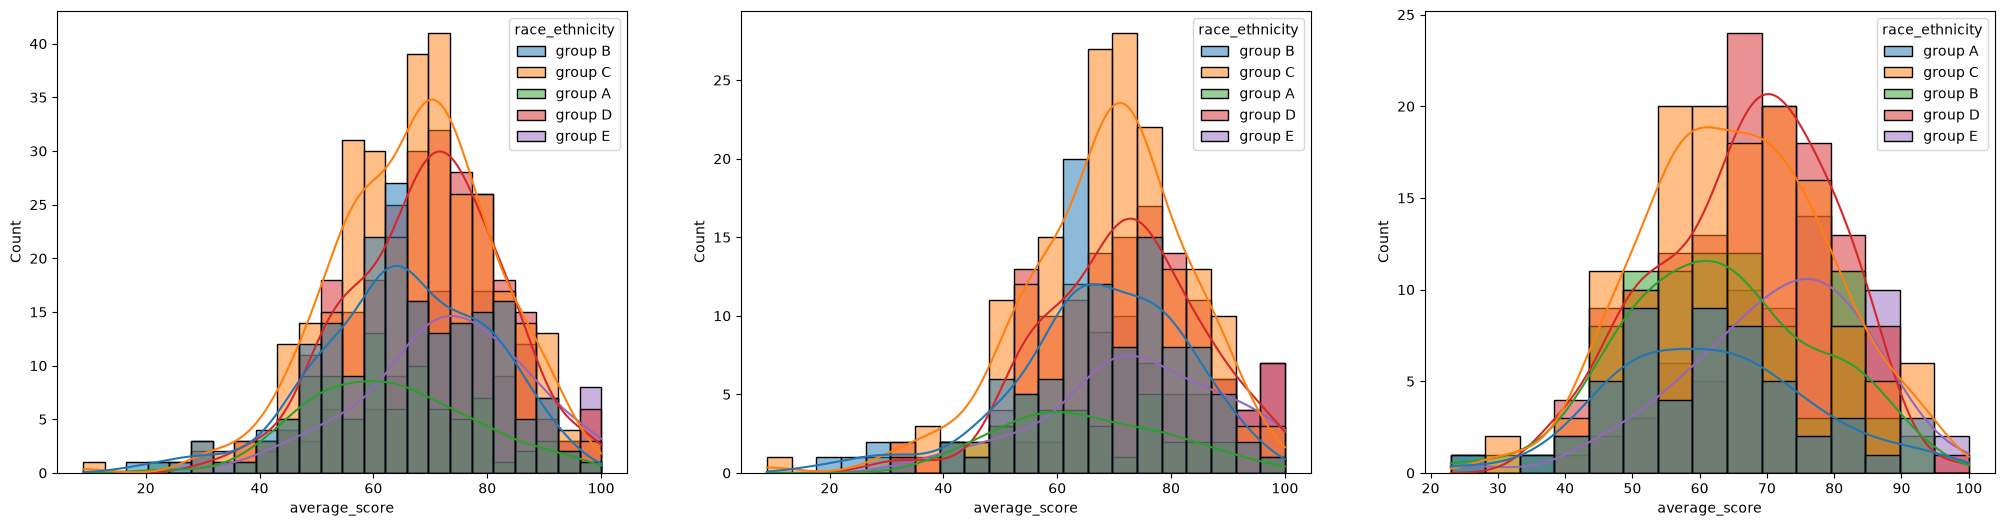

In [30]:
plt.subplots(1, 3, figsize=(25, 6))

plt.subplot(131)
ax = sns.histplot(data=df, x='average_score', kde=True, hue='race_ethnicity')

plt.subplot(132)
ax = sns.histplot(data=df[df['gender']=='female'], x='average_score', kde=True, hue='race_ethnicity')

plt.subplot(133)
ax = sns.histplot(data=df[df['gender']=='male'], x='average_score', kde=True, hue='race_ethnicity')

plt.show()

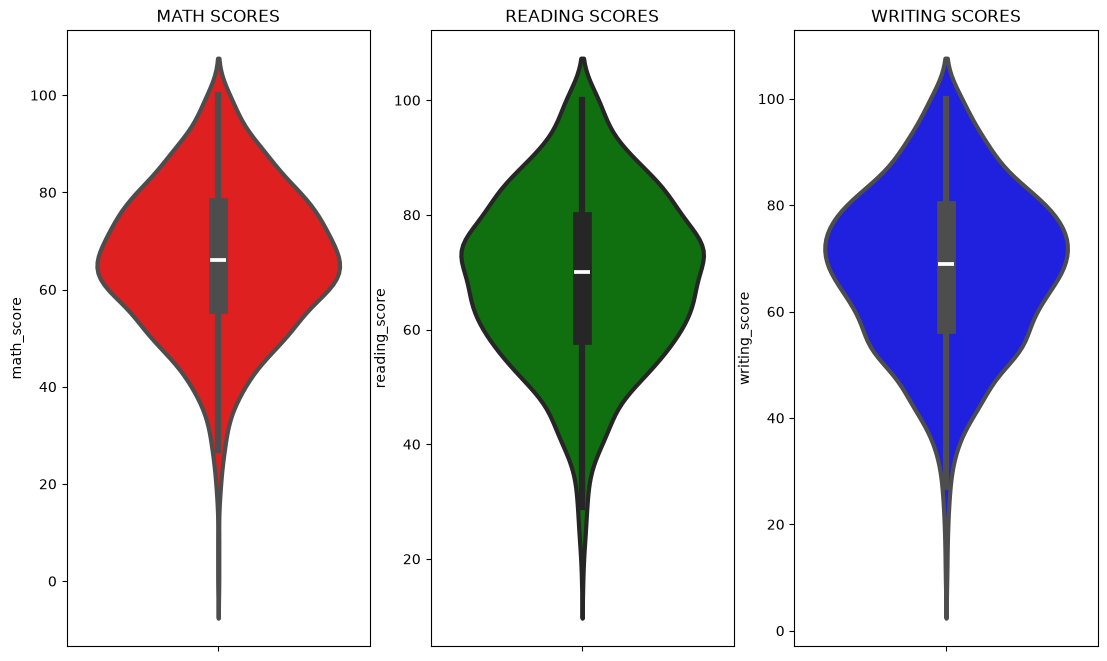

In [31]:
plt.figure(figsize=(18,8))
plt.subplot(1, 4, 1)
plt.title('MATH SCORES')
sns.violinplot(y='math_score',data=df,color='red',linewidth=3)
plt.subplot(1, 4, 2)
plt.title('READING SCORES')
sns.violinplot(y='reading_score',data=df,color='green',linewidth=3)
plt.subplot(1, 4, 3)
plt.title('WRITING SCORES')
sns.violinplot(y='writing_score',data=df,color='blue',linewidth=3)
plt.show()

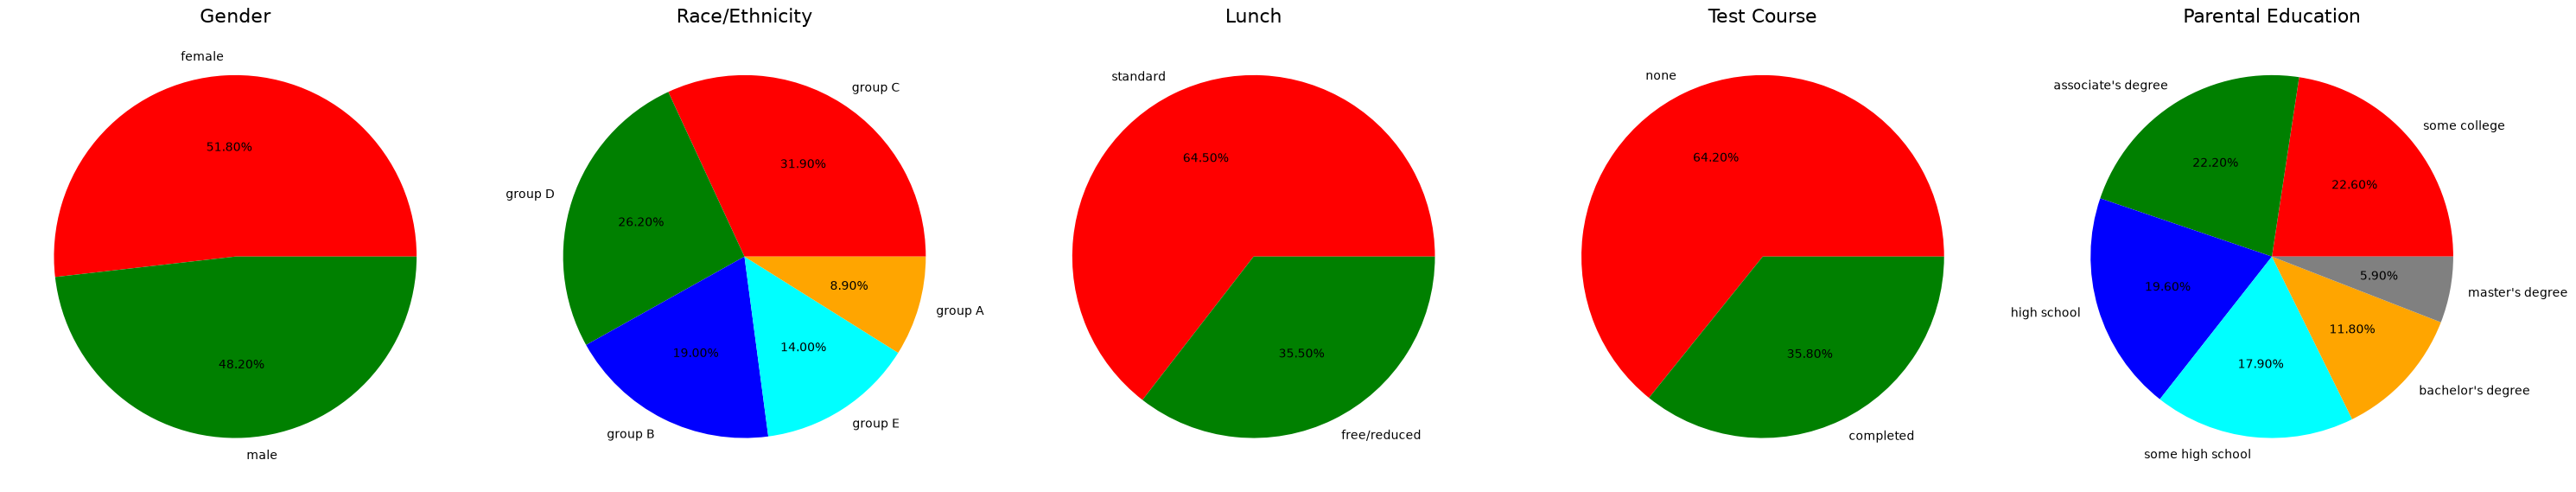

In [32]:
import matplotlib.pyplot as plt

# تحديد حجم الشكل العام
plt.figure(figsize=(30, 8))

# 1. Gender
plt.subplot(1, 5, 1)
size = df['gender'].value_counts()
plt.pie(size, colors=['red', 'green'], labels=size.index, autopct='%.2f%%')
plt.title('Gender', fontsize=16)

# 2. Race/Ethnicity
plt.subplot(1, 5, 2)
size = df['race_ethnicity'].value_counts()
plt.pie(size, colors=['red', 'green', 'blue', 'cyan', 'orange'], labels=size.index, autopct='%.2f%%')
plt.title('Race/Ethnicity', fontsize=16)

# 3. Lunch
plt.subplot(1, 5, 3)
size = df['lunch'].value_counts()
plt.pie(size, colors=['red', 'green'], labels=size.index, autopct='%.2f%%')
plt.title('Lunch', fontsize=16)

# 4. Test Preparation Course
plt.subplot(1, 5, 4)
size = df['test_preparation_course'].value_counts()
plt.pie(size, colors=['red', 'green'], labels=size.index, autopct='%.2f%%')
plt.title('Test Course', fontsize=16)

# 5. Parental Level of Education
plt.subplot(1, 5, 5)
size = df['parental_level_of_education'].value_counts()
plt.pie(size, colors=['red', 'green', 'blue', 'cyan', 'orange', 'grey'], labels=size.index, autopct='%.2f%%')
plt.title('Parental Education', fontsize=16)

plt.tight_layout()
plt.show()

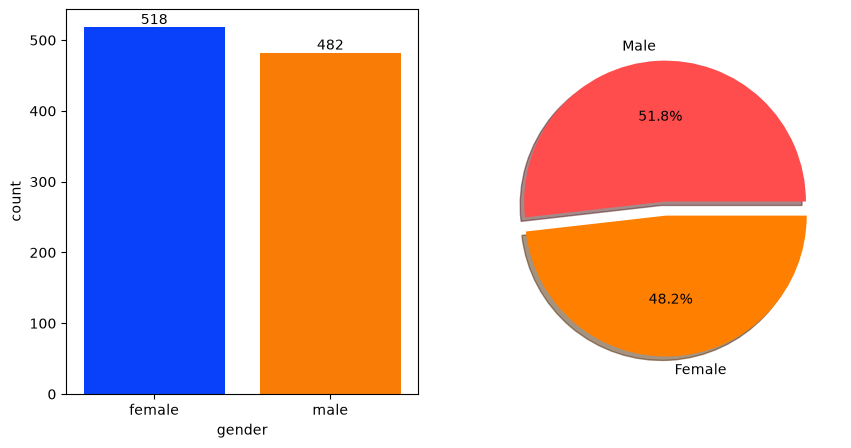

In [37]:
f, ax = plt.subplots(1, 2, figsize=(10, 5))

# 1. Bar Chart with Data Labels
sns.countplot(x=df['gender'], data=df, palette='bright', ax=ax[0], saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container, color='black', size=10)

# 2. Pie Chart
plt.pie(x=df['gender'].value_counts(), labels=['Male', 'Female'], explode=[0, 0.1], 
        autopct='%1.1f%%', shadow=True, colors=['#ff4d4d', '#ff8000'])

plt.show()

In [40]:

numeric_cols = df.select_dtypes(include='number').columns.tolist() + ['gender']
gender_group = df[numeric_cols].groupby('gender').mean()

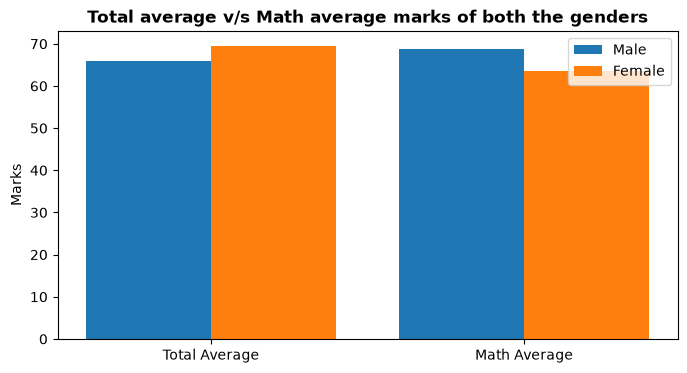

In [42]:
import numpy as np
import matplotlib.pyplot as plt

# 1. التجميع وحساب المتوسط
gender_group = df.groupby('gender')[['average_score', 'math_score']].mean()

plt.figure(figsize=(8, 4))

X = ['Total Average', 'Math Average']

female_scores = [gender_group.loc['female', 'average_score'], gender_group.loc['female', 'math_score']]
male_scores = [gender_group.loc['male', 'average_score'], gender_group.loc['male', 'math_score']]

X_axis = np.arange(len(X))

# 2. رسم الأعمدة المقارنة
plt.bar(X_axis - 0.2, male_scores, 0.4, label='Male')
plt.bar(X_axis + 0.2, female_scores, 0.4, label='Female')

plt.xticks(X_axis, X)
plt.ylabel("Marks")
plt.title("Total average v/s Math average marks of both the genders", fontweight='bold')
plt.legend()
plt.show()

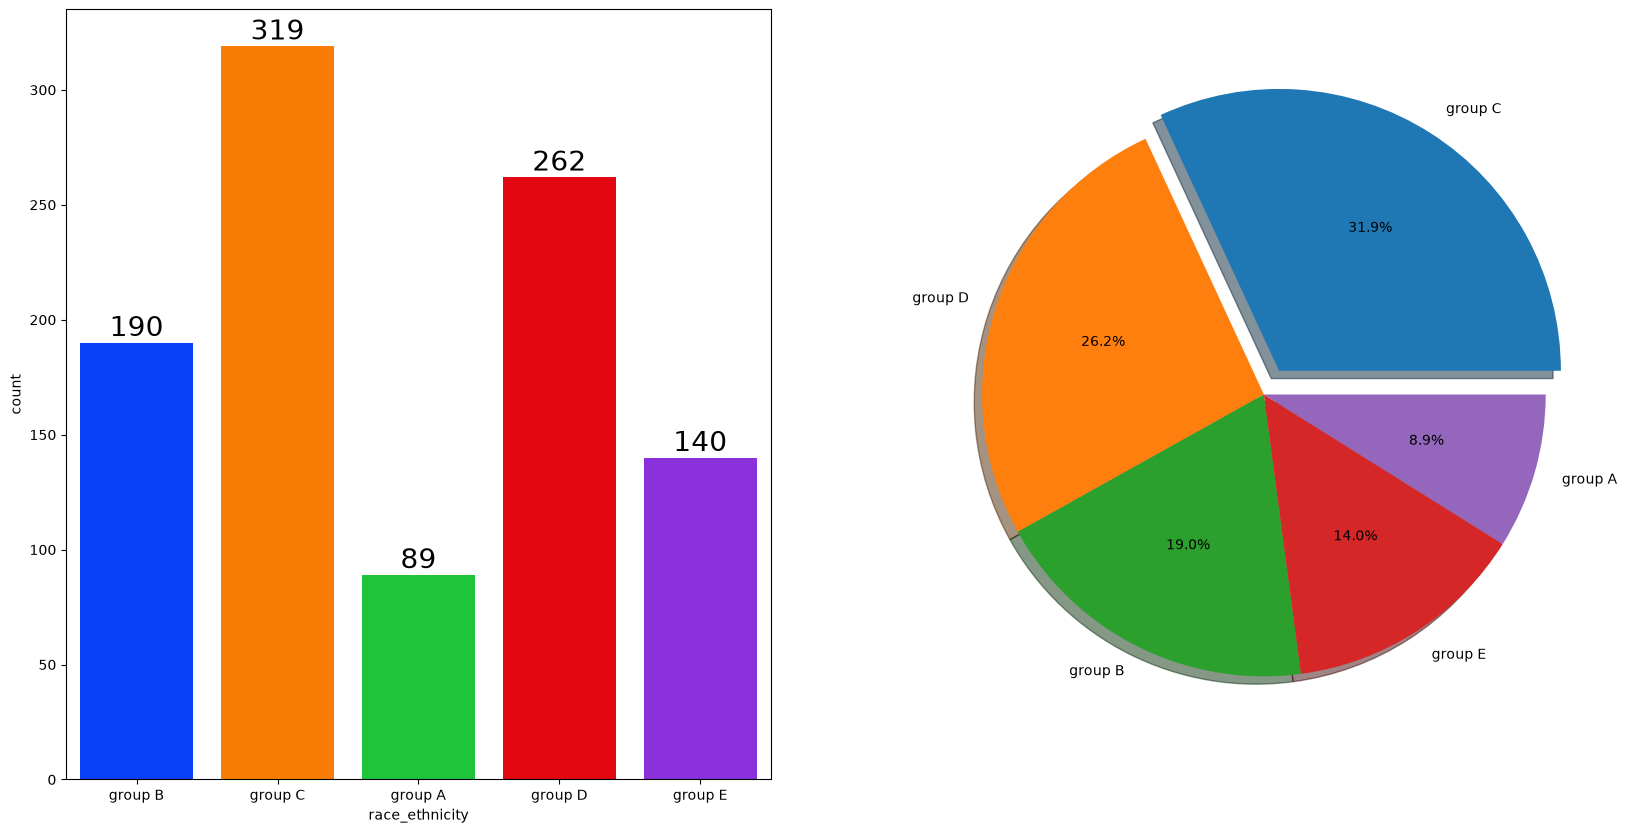

In [44]:
f, ax = plt.subplots(1, 2, figsize=(20, 10))

# Bar chart
sns.countplot(x=df['race_ethnicity'], data=df, palette='bright', ax=ax[0], saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container, color='black', size=20)

# Pie chart
plt.pie(x=df['race_ethnicity'].value_counts(), 
        labels=df['race_ethnicity'].value_counts().index, 
        explode=[0.1, 0, 0, 0, 0], 
        autopct='%1.1f%%', 
        shadow=True)
plt.show()

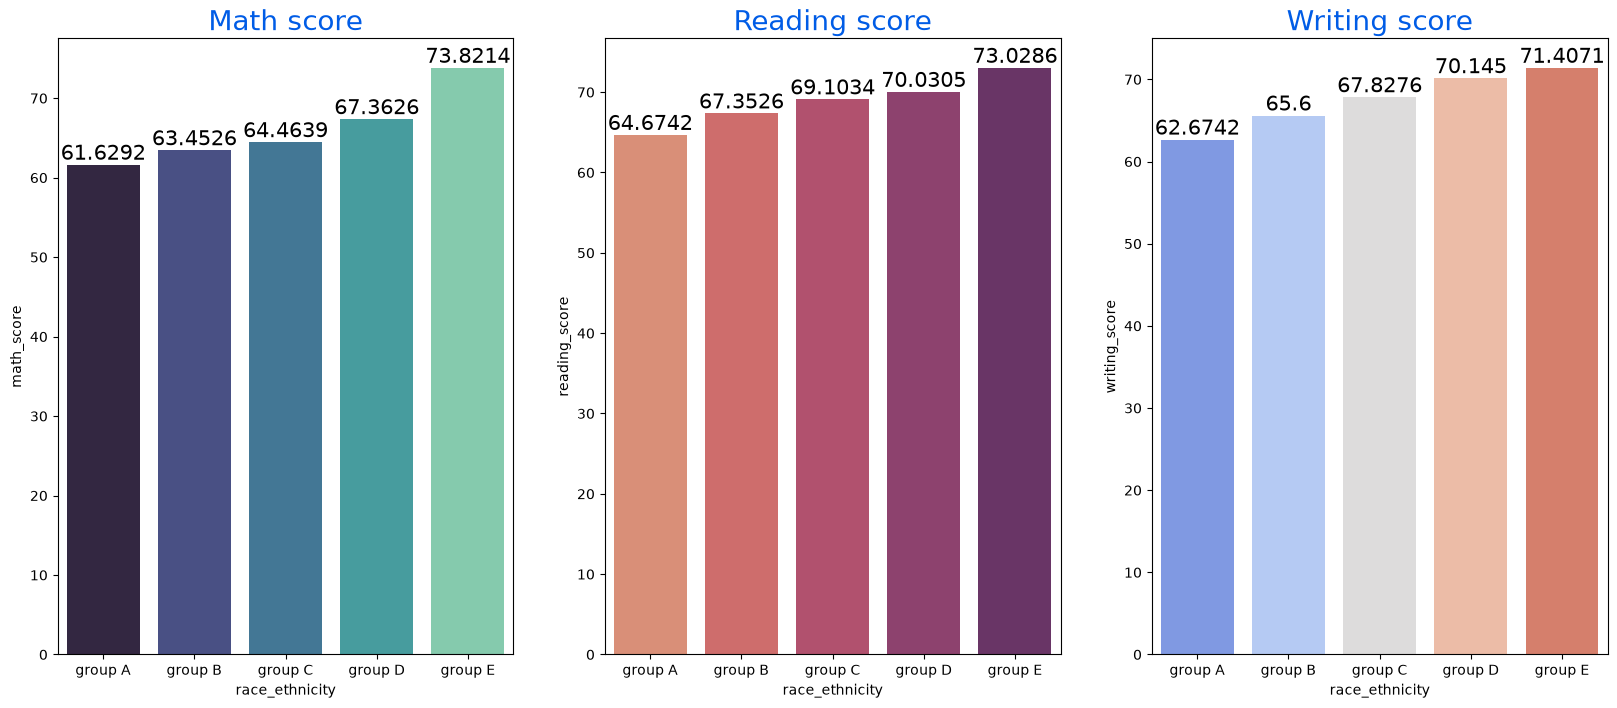

In [46]:
# تجميع البيانات وحساب المتوسط لكل المواد
group_data = df.groupby('race_ethnicity')[['math_score', 'reading_score', 'writing_score']].mean()

f, ax = plt.subplots(1, 3, figsize=(20, 8))

# 1. Math Score
sns.barplot(x=group_data.index, y=group_data['math_score'], palette='mako', ax=ax[0])
ax[0].set_title('Math score', color='#005ce6', size=20)
for container in ax[0].containers:
    ax[0].bar_label(container, color='black', size=15)

# 2. Reading Score
sns.barplot(x=group_data.index, y=group_data['reading_score'], palette='flare', ax=ax[1])
ax[1].set_title('Reading score', color='#005ce6', size=20)
for container in ax[1].containers:
    ax[1].bar_label(container, color='black', size=15)

# 3. Writing Score
sns.barplot(x=group_data.index, y=group_data['writing_score'], palette='coolwarm', ax=ax[2])
ax[2].set_title('Writing score', color='#005ce6', size=20)
for container in ax[2].containers:
    ax[2].bar_label(container, color='black', size=15)

plt.show()

findfont: Failed to find font weight 30 for DejaVu Sans, now using 400.


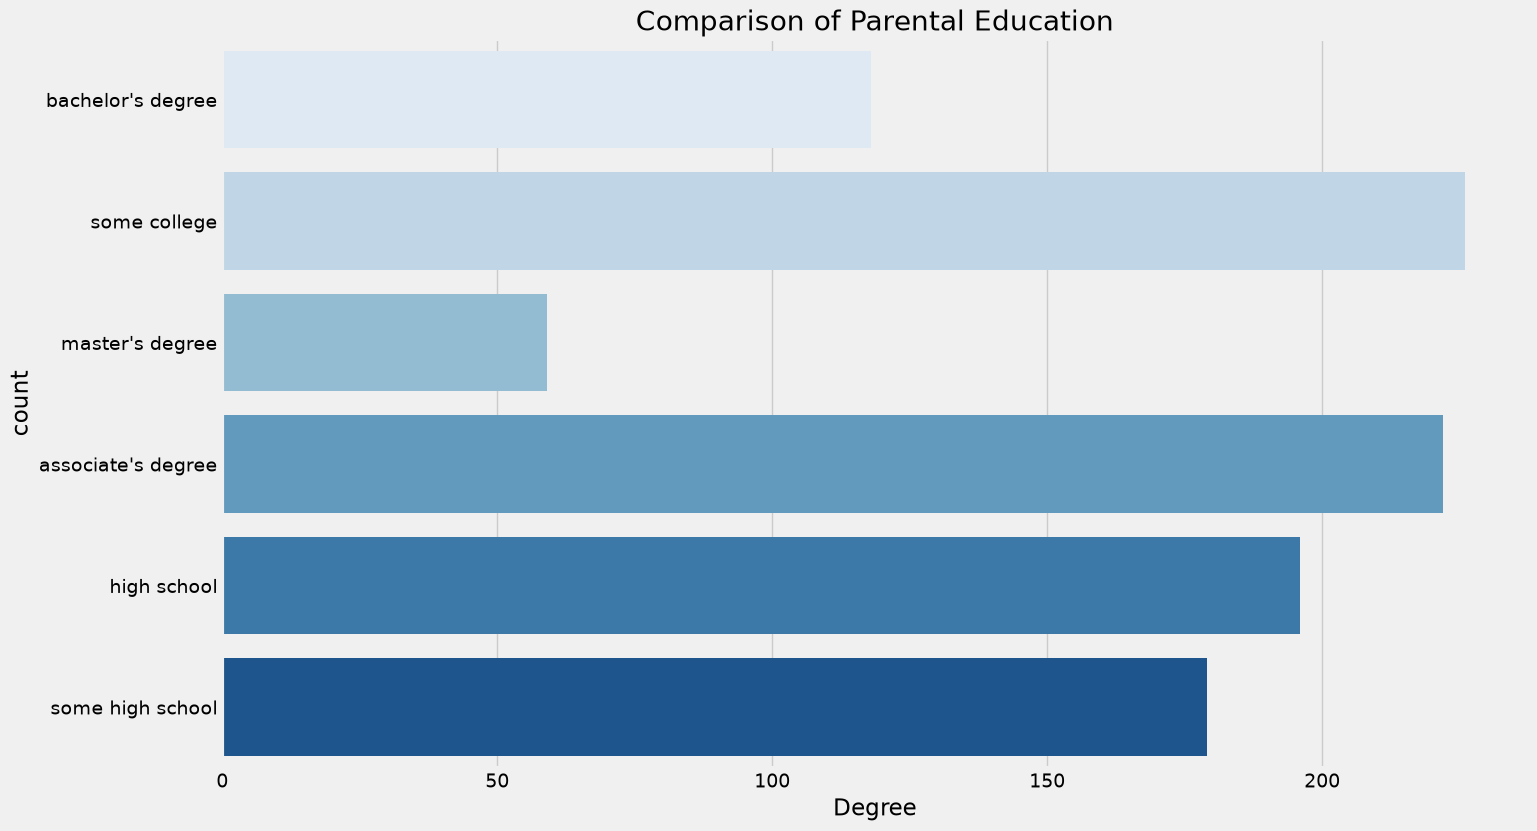

In [47]:
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('fivethirtyeight')
sns.countplot(df['parental_level_of_education'], palette = 'Blues')
plt.title('Comparison of Parental Education', fontweight = 30, fontsize = 20)
plt.xlabel('Degree')
plt.ylabel('count')
plt.show()

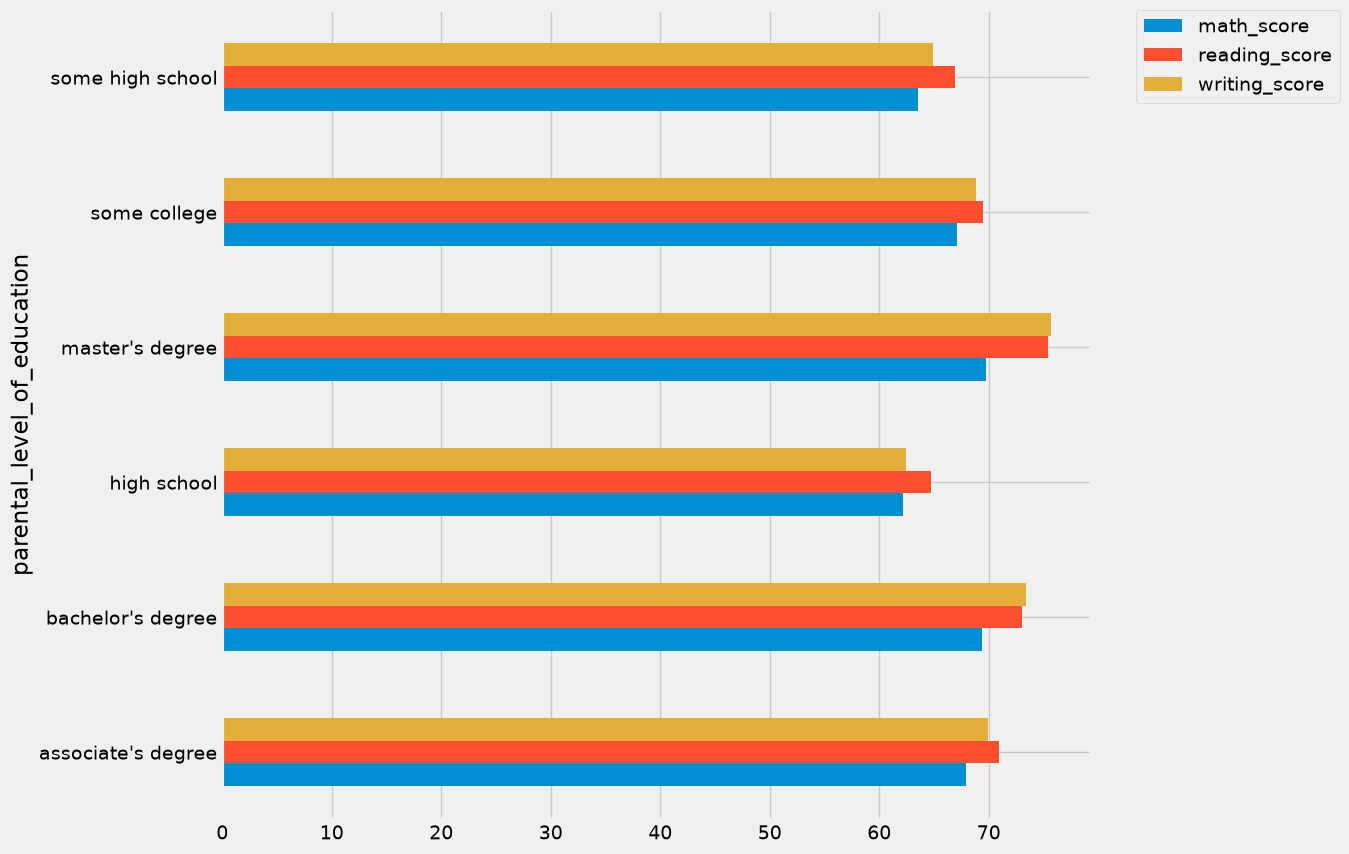

In [49]:
df.groupby('parental_level_of_education')[['math_score', 'reading_score', 'writing_score']].mean().plot(kind='barh', figsize=(10, 10))
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.show()

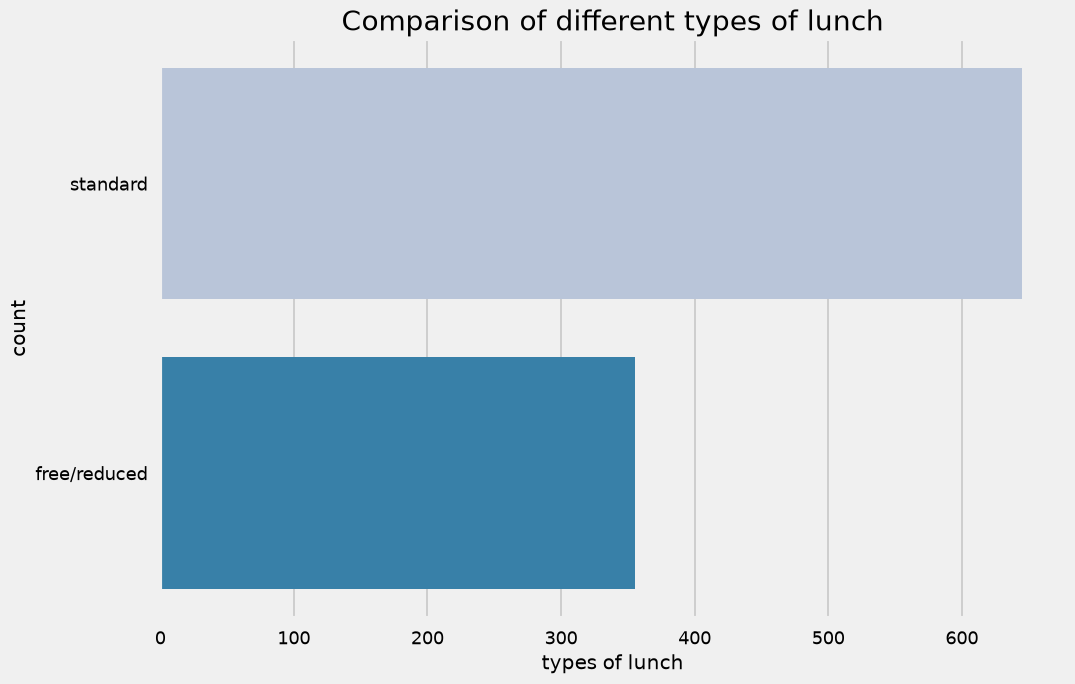

In [51]:
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('seaborn-v0_8-talk')
sns.countplot(df['lunch'], palette='PuBu')
plt.title('Comparison of different types of lunch', fontweight=30, fontsize=20)
plt.xlabel('types of lunch')
plt.ylabel('count')
plt.show()

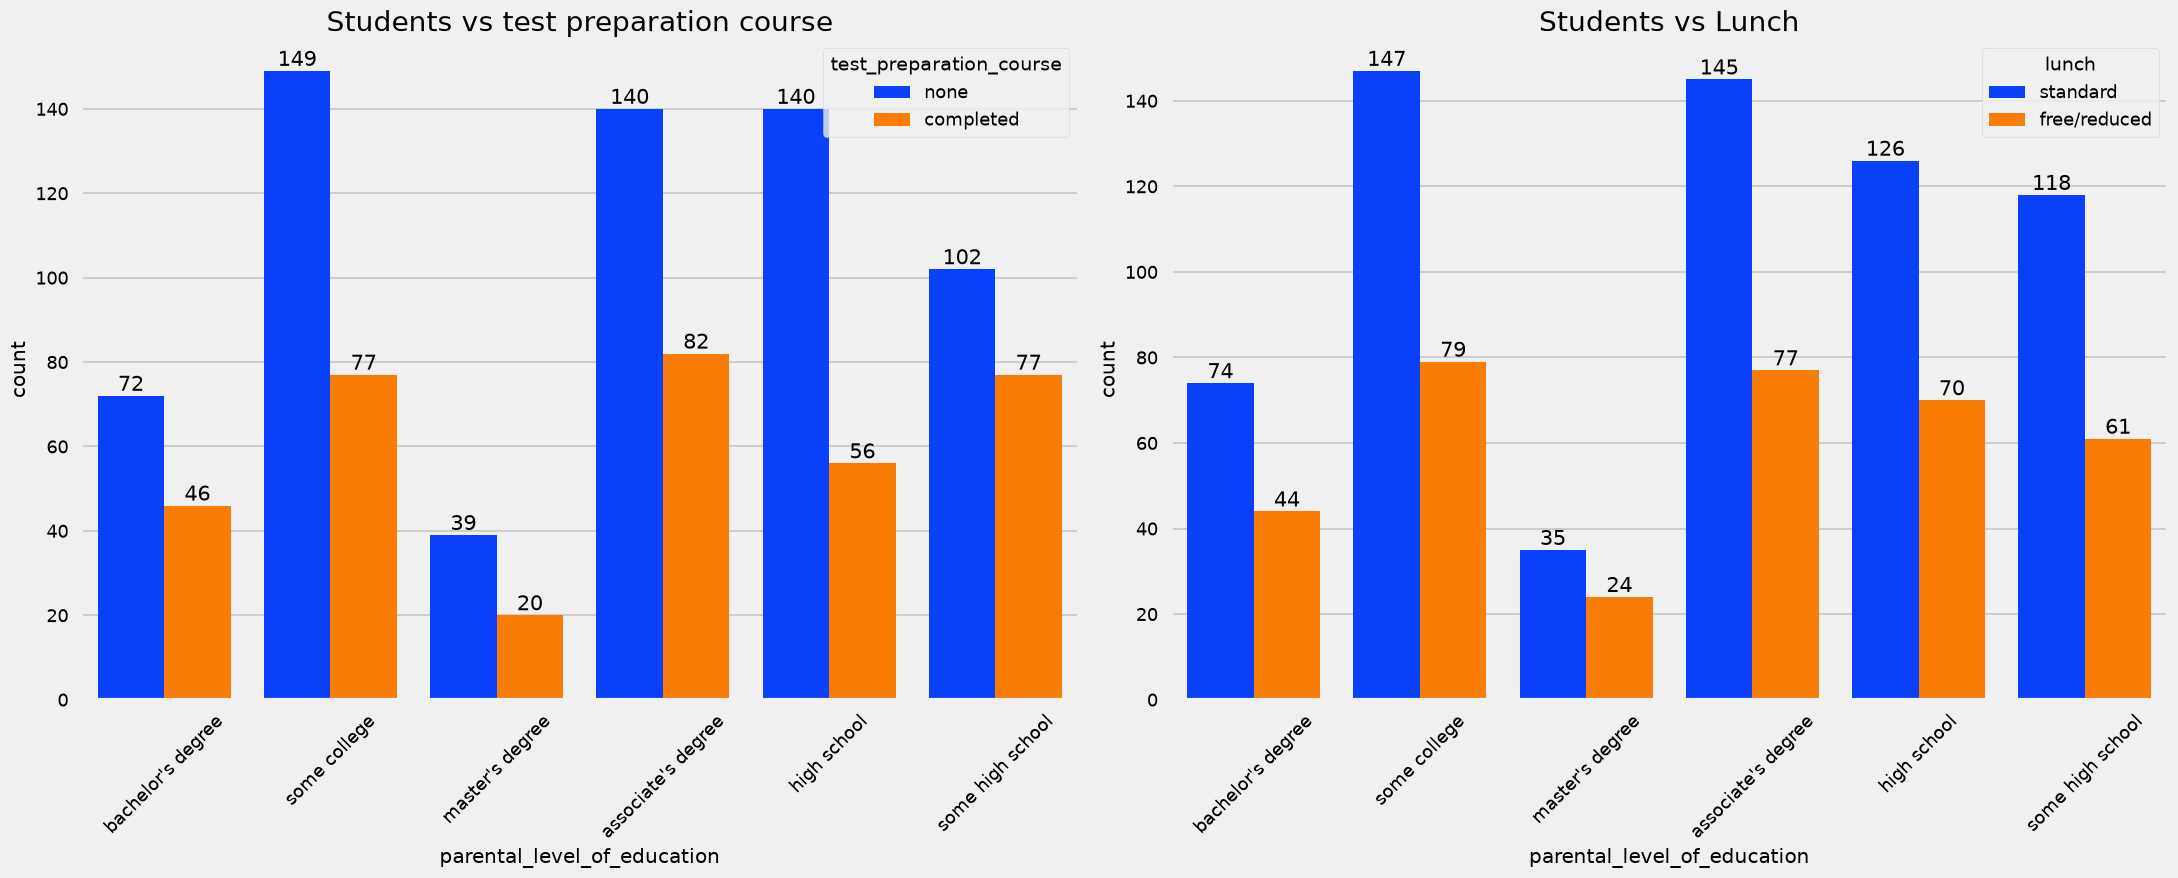

In [53]:
f, ax = plt.subplots(1, 2, figsize=(22, 9))
sns.countplot(x=df['parental_level_of_education'], data=df, palette='bright', hue='test_preparation_course', saturation=0.95, ax=ax[0])
ax[0].set_title('Students vs test preparation course', color='black', size=20)
for container in ax[0].containers:
    ax[0].bar_label(container, color='black', size=15)
ax[0].tick_params(axis='x', rotation=45)
sns.countplot(x=df['parental_level_of_education'], data=df, palette='bright', hue='lunch', saturation=0.95, ax=ax[1])
ax[1].set_title('Students vs Lunch', color='black', size=20)
for container in ax[1].containers:
    ax[1].bar_label(container, color='black', size=15)
ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

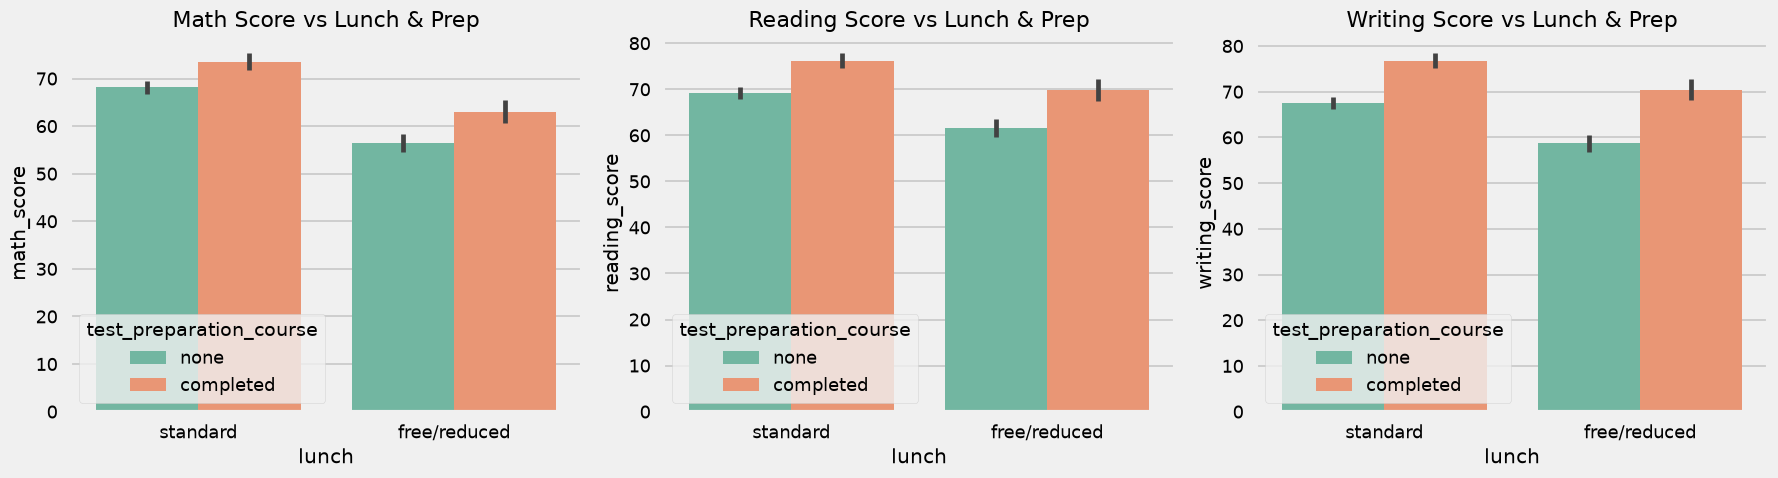

In [55]:
plt.figure(figsize=(18, 5))

# 1. Math Score
plt.subplot(1, 3, 1)
sns.barplot(data=df, x='lunch', y='math_score', hue='test_preparation_course', palette='Set2')
plt.title('Math Score vs Lunch & Prep')

# 2. Reading Score
plt.subplot(1, 3, 2)
sns.barplot(data=df, x='lunch', y='reading_score', hue='test_preparation_course', palette='Set2')
plt.title('Reading Score vs Lunch & Prep')

# 3. Writing Score
plt.subplot(1, 3, 3)
sns.barplot(data=df, x='lunch', y='writing_score', hue='test_preparation_course', palette='Set2')
plt.title('Writing Score vs Lunch & Prep')

plt.tight_layout()
plt.show()

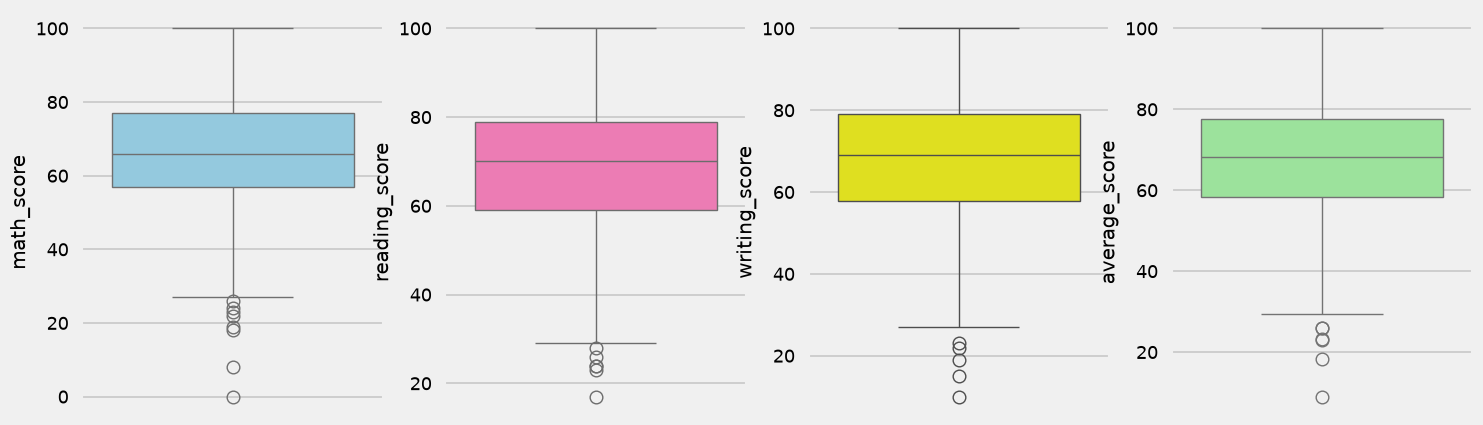

In [57]:
plt.subplots(1,4,figsize=(16,5))
plt.subplot(141)
sns.boxplot(df['math_score'],color='skyblue')
plt.subplot(142)
sns.boxplot(df['reading_score'],color='hotpink')
plt.subplot(143)
sns.boxplot(df['writing_score'],color='yellow')
plt.subplot(144)
sns.boxplot(df['average_score'],color='lightgreen')
plt.show()

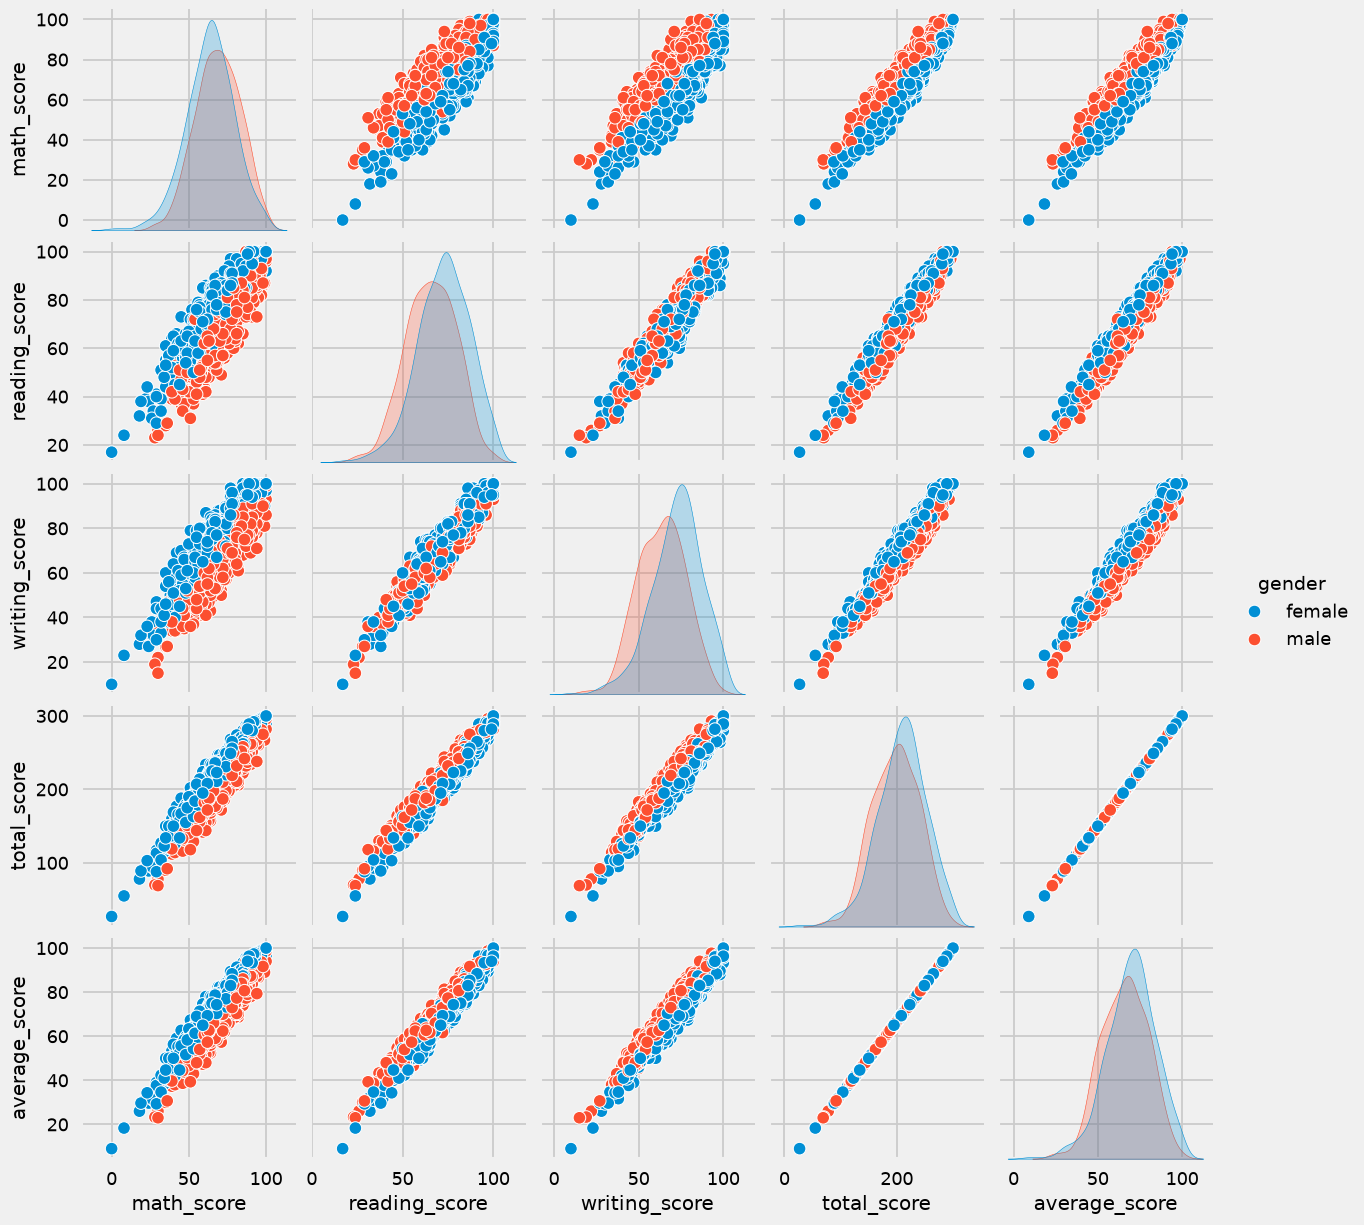

In [58]:
sns.pairplot(df,hue = 'gender')
plt.show()